q50 = [0.125 0.    0.75  0.    0.125]
q51 = [0.  0.5 0.  0.5 0. ]


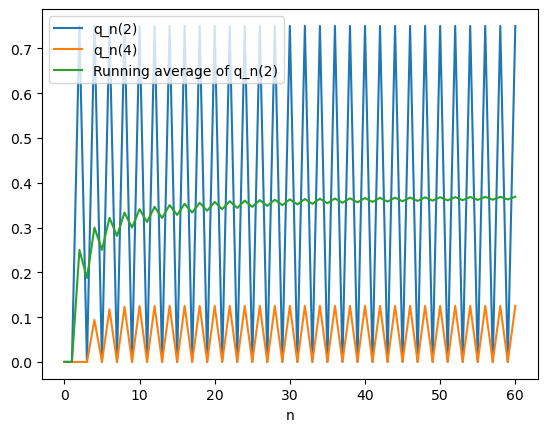

In [3]:

import numpy as np
import matplotlib.pyplot as plt

a, b = 1, 1

P = np.zeros((5, 5))

for k in range(5):
    if k < 4:
        P[k, k+1] = a * (4-k) / 4
    if k > 0:
        P[k, k-1] = b * k / 4
    P[k, k] = 1 - np.sum(P[k])

q = np.array([1., 0., 0., 0., 0.])
q_values = [q.copy()]

for n in range(60):
    q = q @ P
    q_values.append(q.copy())

q_values = np.array(q_values)

print("q50 =", q_values[50])
print("q51 =", q_values[51])

n = np.arange(61)
running_avg = np.cumsum(q_values[:, 2]) / (n + 1)

plt.plot(n, q_values[:, 2], label="q_n(2)")
plt.plot(n, q_values[:, 4], label="q_n(4)")
plt.plot(n, running_avg, label="Running average of q_n(2)")

plt.xlabel("n")
plt.legend()
plt.show()


Stationary d: [0.00390625 0.046875   0.2109375  0.421875   0.31640625]
Binomial d: [0.00390625 0.046875   0.2109375  0.421875   0.31640625]
Smallest n: 134
Eigenvalues: [0.6 0.7 0.8 0.9 1. ]


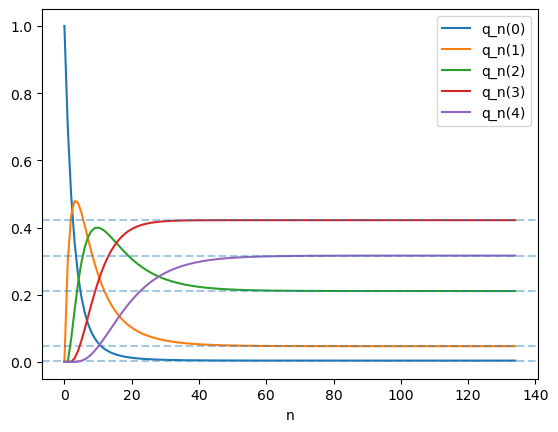

In [13]:
from math import comb

a, b = 0.3, 0.1

P = np.zeros((5, 5))

for k in range(5):
    if k < 4:
        P[k, k+1] = a * (4-k) / 4
    if k > 0:
        P[k, k-1] = b * k / 4
    P[k, k] = 1 - np.sum(P[k])

A = P.T - np.eye(5)
A[-1, :] = np.ones(5)
rhs = np.zeros(5)
rhs[-1] = 1

pi = np.linalg.solve(A, rhs)

theta = a / (a + b)
pi_binomial = np.array([
    comb(4, k) * theta**k * (1-theta)**(4-k)
    for k in range(5)])

print("Stationary d:", pi)
print("Binomial d:", pi_binomial)

q = np.array([1., 0., 0., 0., 0.])
q_values = [q.copy()]

tol = 1e-6
first_n = None

for n in range(1, 1000):
    q = q @ P
    q_values.append(q.copy())

    if np.max(np.abs(q - pi)) < tol:
        first_n = n
        break

print("Smallest n:", first_n)

eigenvalues = np.linalg.eigvals(P)

print("Eigenvalues:", eigenvalues)

q_values = np.array(q_values)

for k in range(5):
    plt.plot(q_values[:, k], label=f"q_n({k})")
    plt.axhline(pi[k], linestyle="--", alpha=0.4)

plt.xlabel("n")
plt.legend()
plt.show()

#Graphs shows they converge!

In [15]:
P = np.array([
    [0, 1/2, 1/2, 0, 0, 0, 0, 0],
    [0, 0, 1/2, 1/2, 0, 0, 0, 0],
    [1/2, 0, 0, 0, 1/2, 0, 0, 0],
    [1/3, 0, 1/3, 0, 1/3, 0, 0, 0],
    [0, 1/3, 0, 0, 0, 1/3, 1/3, 0],
    [0, 0, 0, 0, 0, 1, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 1],
    [0, 0, 0, 0, 0, 0, 1, 0]
])

q = np.ones(8) / 8

for n in range(1, 102):
    q = q @ P
    if n == 100:
        print("q100 =", q)
    if n == 101:
        print("q101 =", q)


q100 = [5.35201377e-08 5.16600068e-08 7.24662674e-08 2.99187156e-08
 5.35201377e-08 4.37499869e-01 2.67736426e-01 2.94763443e-01]
q101 = [4.62060389e-08 4.46001148e-08 6.25629775e-08 2.58300034e-08
 4.62060389e-08 4.37499887e-01 2.94763461e-01 2.67736426e-01]


In [21]:
d = 0.85
G = d * P + (1-d)/8 * np.ones((8, 8))

q = np.ones(8) / 8

for n in range(1, 100000):
    q_new = q @ G

    if np.linalg.norm(q_new - q, 1) < 1e-10:
        q = q_new
        break

    q = q_new

print("Iteration:", n)
print("Pi:", q)

A = G.T - np.eye(8)
A[-1, :] = 1

b = np.zeros(8)
b[-1] = 1

pi = np.linalg.solve(A, b)

print("Linear solve:", pi)

print("rank:", np.argsort(-pi) + 1)


Iteration: 124
Pi: [0.07175665 0.06957763 0.09250788 0.04832049 0.07175665 0.26054035
 0.19826505 0.18727529]
Linear solve: [0.07175665 0.06957763 0.09250788 0.04832049 0.07175665 0.26054035
 0.19826505 0.18727529]
rank: [6 7 8 3 5 1 2 4]


pi: [0.07175665 0.06957763 0.09250788 0.04832049 0.07175665 0.26054035
 0.19826505 0.18727529]
Estimated pi: [0.0718206 0.0696451 0.0924454 0.048337  0.0717168 0.2601765 0.1984273
 0.1874313]


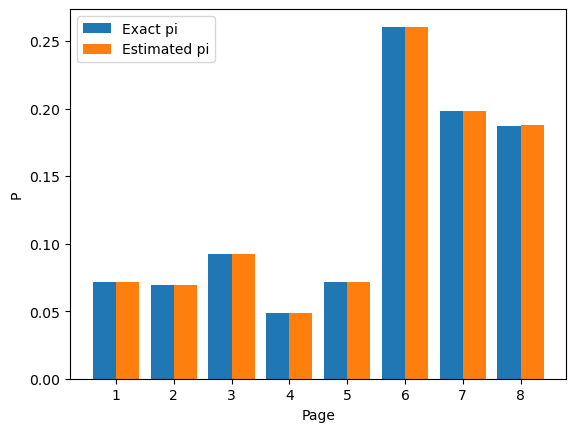

In [29]:
R = 100
T = 100000

rng = np.random.default_rng(42)

positions = np.zeros(R, dtype=int)

cdf = np.cumsum(G, axis=1)

counts = np.zeros(8, dtype=int)

checkpoints = np.unique(
    np.logspace(2, 5, 40).astype(int)
)

errors = []
one_surfer_estimate = None

for t in range(1, T + 1):

    u = rng.random(R)

    next_positions = np.sum(
        u[:, None] > cdf[positions], axis=1
    )

    positions = next_positions

    counts += np.bincount(positions, minlength=8)

    if t == T:
        pass

    if t in checkpoints:
        pi_hat_t = counts / (R * t)
        errors.append(np.max(np.abs(pi_hat_t - pi)))

pi_hat = counts / (R * T)

print("pi:", pi)
print("Estimated pi:", pi_hat)

pages = np.arange(1, 9)

plt.figure()
plt.bar(pages - 0.2, pi, width=0.4, label="Exact pi")
plt.bar(pages + 0.2, pi_hat, width=0.4, label="Estimated pi")
plt.xlabel("Page")
plt.ylabel("P")
plt.legend()
plt.show()


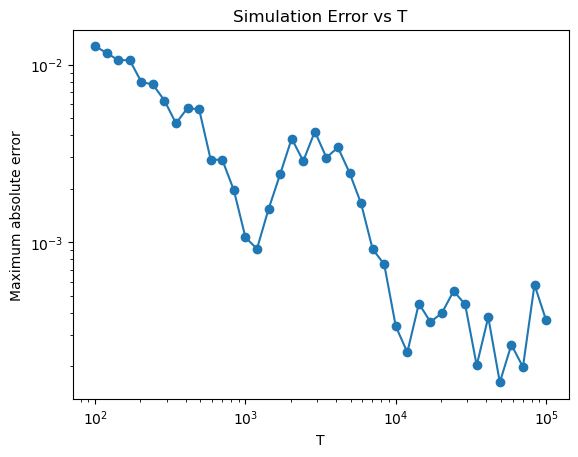

In [27]:
plt.figure()
plt.loglog(checkpoints, errors, marker="o")
plt.xlabel("T")
plt.ylabel("Maximum absolute error")
plt.title("Simulation Error vs T")
plt.show()